Correct value of s = 0.33205680847167973
Initial values: [0.         0.         0.33205681]
Second values: [0.00166028 0.03320568 0.33204762]
Final values: [8.27922731e+00 1.00000055e+00 8.22025219e-09]
Step size = 0.4   s = 0.33197746276855455
Step size = 0.2   s = 0.33204994201660154
Step size = 0.1   s = 0.3320568084716796
Step size = 0.05   s = 0.3320575714111328
Step size = 0.025   s = 0.3320575714111328

All calculated s values:
[0.33197746276855455, 0.33204994201660154, 0.3320568084716796, 0.3320575714111328, 0.3320575714111328]


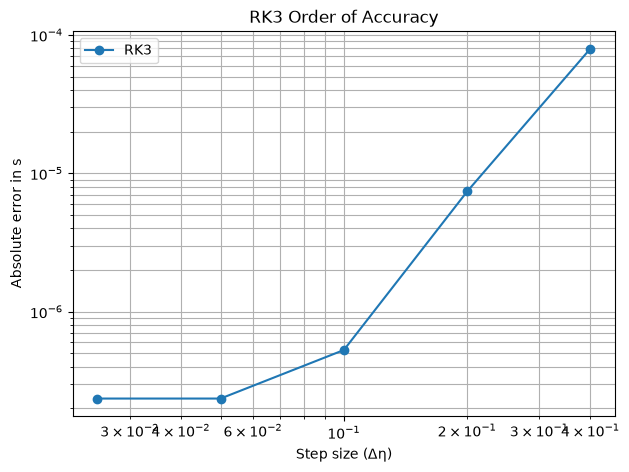

Observed order of accuracy = 2.1789873142956937


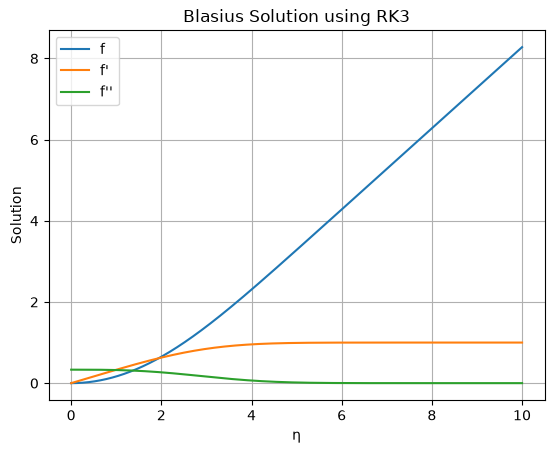

h = 0.4 s = 0.33205909729003913
h = 0.2 s = 0.3320575714111329
h = 0.1 s = 0.3320575714111329
h = 0.05 s = 0.3320575714111329
h = 0.025 s = 0.3320575714111329


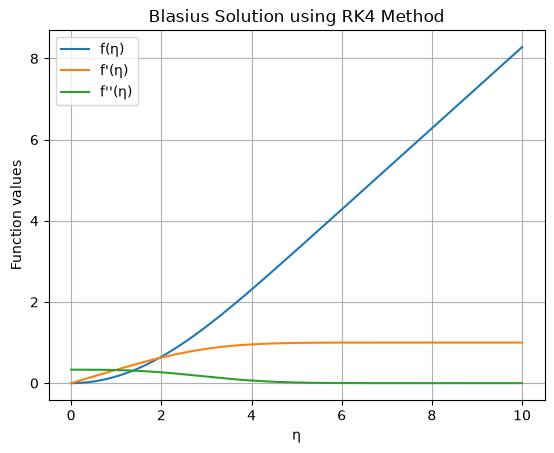

RK3 Results
h = 0.4 s = 0.33197746276855455 Rounded s = 0.332
h = 0.2 s = 0.33204994201660154 Rounded s = 0.332
h = 0.1 s = 0.3320568084716796 Rounded s = 0.332
h = 0.05 s = 0.3320575714111328 Rounded s = 0.332
h = 0.025 s = 0.3320575714111328 Rounded s = 0.332

RK4 Results
h = 0.4 s = 0.33205909729003913 Rounded s = 0.332
h = 0.2 s = 0.3320575714111329 Rounded s = 0.332
h = 0.1 s = 0.3320575714111329 Rounded s = 0.332
h = 0.05 s = 0.3320575714111329 Rounded s = 0.332
h = 0.025 s = 0.3320575714111329 Rounded s = 0.332


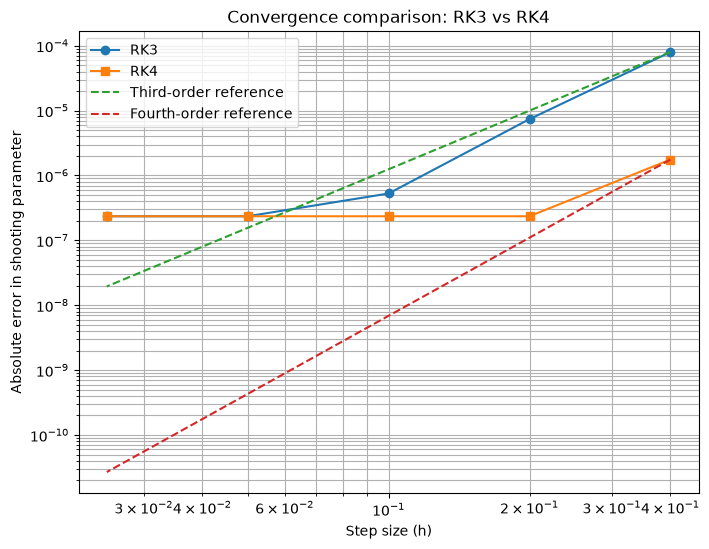

In [1]:

import numpy as np

def G(Y):
    return np.array([Y[1], Y[2], -0.5*Y[0]*Y[2]])        ##Y[1]=f'  Y[2]=f"  Y[0]=f

## Defining RK3 method

def RK3(Y, h):

    K1 = G(Y)

    K2 = G(Y + h*K1/2)

    K3 = G(Y - h*K1 + 2*h*K2)

    Y_new = Y + h*(K1 + 4*K2 + K3)/6

    return Y_new

## integrating rk3 method

def solve(s, h):

    eta_inf = 10
    N = int(eta_inf/h)

    # Initial conditions
    Y = np.array([0.0, 0.0, s])

    eta = np.linspace(0, eta_inf, N+1)

    Y_values = np.zeros((N+1, 3))

    Y_values[0] = Y

    for i in range(N):

        Y = RK3(Y, h)

        Y_values[i+1] = Y

    return eta, Y_values


def residual(s, h):

    eta, Y_values = solve(s, h)

    r = Y_values[-1][1] - 1

    return r


def bisection(s_low, s_high, h, tol):

    r_low = residual(s_low, h)

    r_high = residual(s_high, h)

    if r_low * r_high > 0:

        print("Invalid initial interval")

        return None

    while abs(s_high - s_low) > tol:

        s_mid = (s_low + s_high)/2

        r_mid = residual(s_mid, h)

        if r_low * r_mid < 0:

            s_high = s_mid

            r_high = r_mid

        else:

            s_low = s_mid

            r_low = r_mid

    return (s_low + s_high)/2


# Initial guesses (Adjusted to contain the root, which is approximately 0.332)
s_low = 0.2
s_high = 0.4

h = 0.1

tol = 1e-6


# Find the correct initial value
s_correct = bisection(s_low, s_high, h, tol)

print("Correct value of s =", s_correct)


# Solve using the correct value of s
eta, Y_values = solve(s_correct, h)

print("Initial values:", Y_values[0])

print("Second values:", Y_values[1])

print("Final values:", Y_values[-1])


# Different step sizes
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]


s_values = []

for h in h_values:

    s = bisection(0.3, 0.4, h, 1e-6)

    s_values.append(s)

    print("Step size =", h, "  s =", s)

print("\nAll calculated s values:")
print(s_values)


import matplotlib.pyplot as plt


s_exact = 0.332057336215

# Calculate absolute error
error = np.abs(np.array(s_values) - s_exact)

# Log-log plot
plt.figure(figsize=(7,5))

plt.loglog(h_values, error, 'o-', label='RK3')

plt.xlabel('Step size (Δη)')
plt.ylabel('Absolute error in s')

plt.title('RK3 Order of Accuracy')

plt.grid(True, which='both')
plt.legend()

plt.show()

# Calculate slope of log-log plot
slope = np.polyfit(np.log(h_values),
                   np.log(error), 1)[0]

print("Observed order of accuracy =", slope)


# Initial parameters
s = 0.332057336
h = 0.01

# Solve the Blasius equation
eta, Y_values = solve(s, h)

# Extract the three variables
f = Y_values[:, 0]
fp = Y_values[:, 1]
fpp = Y_values[:, 2]

# Plot
plt.plot(eta, f, label="f")
plt.plot(eta, fp, label="f'")
plt.plot(eta, fpp, label="f''")

plt.xlabel("η")
plt.ylabel("Solution")
plt.title("Blasius Solution using RK3")
plt.legend()
plt.grid()

plt.show()


## RK4 SOLVER

def solve_RK4(s, h):

    eta_inf = 10
    N = int(eta_inf/h)

    Y = np.array([0.0, 0.0, s])

    eta = np.linspace(0, eta_inf, N+1)
    Y_values = np.zeros((N+1, 3))

    Y_values[0] = Y

    for i in range(N):

        k1 = G(Y)
        k2 = G(Y + h*k1/2)
        k3 = G(Y + h*k2/2)
        k4 = G(Y + h*k3)

        Y = Y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

        Y_values[i+1] = Y

    return eta, Y_values

##Residual and Bisection

def residual_RK4(s, h):

    eta, Y_values = solve_RK4(s, h)

    return Y_values[-1, 1] - 1


def bisection_RK4(h):

    s_low = 0.2
    s_high = 0.4

    tol = 1e-6

    while abs(s_high - s_low) > tol:

        s_mid = (s_low + s_high)/2

        F_mid = residual_RK4(s_mid, h)
        F_low = residual_RK4(s_low, h)

        if F_mid * F_low < 0:
            s_high = s_mid
        else:
            s_low = s_mid

    return (s_low + s_high)/2


h_values = [0.4, 0.2, 0.1, 0.05, 0.025]

s_values_RK4 = []

for h in h_values:

    s = bisection_RK4(h)

    s_values_RK4.append(s)

    print("h =", h, "s =", s)

h = 0.01

s = s_values_RK4[-1]


eta, Y_values = solve_RK4(s, h)

# Extract solutions
f = Y_values[:, 0]
fp = Y_values[:, 1]
fpp = Y_values[:, 2]

plt.plot(eta, f, label="f(η)")
plt.plot(eta, fp, label="f'(η)")
plt.plot(eta, fpp, label="f''(η)")

plt.xlabel("η")
plt.ylabel("Function values")
plt.title("Blasius Solution using RK4 Method")

plt.legend()
plt.grid(True)
plt.show()


s_exact = 0.332057336215

print("RK3 Results")

for h, s in zip(h_values, s_values):
    print("h =", h, "s =", s,
          "Rounded s =", round(s, 3))


print("\nRK4 Results")

for h, s in zip(h_values, s_values_RK4):
    print("h =", h, "s =", s,
          "Rounded s =", round(s, 3))


# Step sizes
h_values = np.array([0.4, 0.2, 0.1, 0.05, 0.025])

# Exact value of shooting parameter
s_exact = 0.3320573362

# Numerical errors
error_RK3 = np.abs(np.array(s_values) - s_exact)
error_RK4 = np.abs(np.array(s_values_RK4) - s_exact)

# Plot convergence
plt.figure(figsize=(8, 6))

plt.loglog(h_values, error_RK3, 'o-', label='RK3')
plt.loglog(h_values, error_RK4, 's-', label='RK4')

# Reference slopes for expected orders
plt.loglog(h_values, error_RK3[0] * (h_values/h_values[0])**3,
           '--', label='Third-order reference')

plt.loglog(h_values, error_RK4[0] * (h_values/h_values[0])**4,
           '--', label='Fourth-order reference')

plt.xlabel('Step size (h)')
plt.ylabel('Absolute error in shooting parameter')
plt.title('Convergence comparison: RK3 vs RK4')

plt.grid(True, which='both')
plt.legend()
plt.show()


# Numerical Solution of Blasius Equation Using RK3 and RK4 Methods

### 1. Problem Definition

We are given the Blasius differential equation:

$$
f''' + \frac{1}{2}ff'' = 0
$$

Subject to the boundary conditions:

$$
f(0)=0,\qquad f'(0)=0
$$

$$
f'(\infty)=1
$$

The value of the second derivative at the wall is unknown. We define this unknown initial value as:

$$
s=f''(0)
$$

The objective is to determine the correct value of $s$ using the shooting method and solve the differential equation numerically using RK3 and RK4 methods.

### 2. Conversion into First-Order Differential Equations

The third-order Blasius equation is converted into three first-order differential equations by introducing the following variables:

$$
Y_0=f,\qquad Y_1=f',\qquad Y_2=f''
$$

The resulting system is:

$$
\frac{dY_0}{d\eta}=Y_1
$$

$$
\frac{dY_1}{d\eta}=Y_2
$$

$$
\frac{dY_2}{d\eta}=-\frac{1}{2}Y_0Y_2
$$

These equations are represented using the function `G(Y)` in the Python program, which returns the derivatives of the three dependent variables.

### 3. Implementation of RK3 Method

The third-order Runge-Kutta method is implemented to numerically integrate the system of differential equations. The method uses three intermediate stages:

$$
K_1=G(Y_n)
$$

$$
K_2=G\left(Y_n+\frac{hK_1}{2}\right)
$$

$$
K_3=G(Y_n-hK_1+2hK_2)
$$

The updated solution is calculated using:

$$
Y_{n+1}=Y_n+\frac{h}{6}
(K_1+4K_2+K_3)
$$

A Python function named `RK3(Y,h)` is defined to perform one integration step using these equations.

### 4. Numerical Integration Using RK3

A function named `solve(s,h)` is defined to integrate the Blasius equation from $\eta=0$ to $\eta=10$ using the RK3 method. The initial conditions are:

$$
Y(0)=
\begin{bmatrix}
0\\
0\\
s
\end{bmatrix}
$$

The integration interval is divided into smaller steps based on the selected step size $h$. The values of all three dependent variables are stored in the array `Y_values`.

### 5. Residual Function and Bisection Method

The shooting method is used to determine the unknown initial parameter $s$ by satisfying the boundary condition $f'(\infty)=1$. Since numerical integration is performed up to $\eta=10$, the residual function is defined as:

$$
R(s)=f'(10)-1
$$

The bisection method is applied by initially selecting lower and upper estimates of $s$. The interval is repeatedly divided into two halves, and the residual is evaluated at the midpoint. This process continues until the difference between the two limits becomes smaller than the specified tolerance. The final midpoint is taken as the required shooting parameter.

### 6. Calculation of Shooting Parameter for Different Step Sizes Using RK3

The RK3 method is used to calculate the shooting parameter for different integration step sizes:

$$
h=0.4,\;0.2,\;0.1,\;0.05,\;0.025
$$

For each step size, the bisection method is applied to obtain the value of $s$ that satisfies the required boundary condition. All calculated shooting parameters are stored in the list `s_values` for further accuracy analysis.

### 7. Accuracy Analysis of RK3 Method

The accuracy of the RK3 method is examined by calculating the absolute error between the numerical shooting parameter and the reference value:

$$
s_{\text{exact}}=0.332057336215
$$

The absolute error is calculated using:

$$
E=|s_{\text{numerical}}-s_{\text{exact}}|
$$

A log-log plot of absolute error against integration step size is generated to study the convergence behaviour. Since RK3 is a third-order method, the expected relationship is:

$$
E\propto h^3
$$

The slope of the log-log plot is calculated using polynomial fitting to estimate the observed order of accuracy.

### 8. Plotting Blasius Solution Using RK3

The Blasius equation is integrated using the calculated shooting parameter and a step size of $h=0.01$. The numerical values of the following variables are extracted from the solution array:

$$
f(\eta),\qquad f'(\eta),\qquad f''(\eta)
$$

These variables are plotted against the similarity variable $\eta$ to observe the variation of the Blasius function and its derivatives across the boundary layer.

### 9. Implementation of RK4 Method

The fourth-order Runge-Kutta method is implemented to solve the same system of first-order differential equations. This method uses four intermediate stages:

$$
k_1=G(Y_n)
$$

$$
k_2=G\left(Y_n+\frac{hk_1}{2}\right)
$$

$$
k_3=G\left(Y_n+\frac{hk_2}{2}\right)
$$

$$
k_4=G(Y_n+hk_3)
$$

The updated solution is calculated using:

$$
Y_{n+1}=Y_n+\frac{h}{6}
(k_1+2k_2+2k_3+k_4)
$$

A separate function named `solve_RK4(s,h)` is defined to perform numerical integration using this method.

### 10. Residual Function and Bisection Method for RK4

Similar to the RK3 implementation, a residual function is defined for the RK4 method:

$$
R(s)=f'(10)-1
$$

The bisection method is then applied to determine the shooting parameter that satisfies the boundary condition. The procedure is repeated for each selected step size, and the resulting values are stored in the list `s_values_RK4`.

### 11. Plotting Blasius Solution Using RK4

The Blasius equation is integrated using the RK4 method, and the numerical values of the following variables are extracted from the solution array:

$$
f(\eta),\qquad f'(\eta),\qquad f''(\eta)
$$

These three variables are plotted against the similarity variable $\eta$ to obtain the Blasius solution using the fourth-order Runge-Kutta method.

### 12. Comparison of RK3 and RK4 Results

The shooting parameters obtained using RK3 and RK4 are printed for all the selected step sizes. The calculated values are rounded to three decimal places and compared with the reference value:

$$
f''(0)\approx 0.332057336215
$$

This comparison helps evaluate the accuracy of both numerical integration methods and examine how the calculated shooting parameter changes with the integration step size.

### 13. Convergence Comparison Between RK3 and RK4

The absolute errors obtained from the RK3 and RK4 methods are calculated using the same reference value of the shooting parameter:

$$
E_{RK3}=|s_{RK3}-s_{\text{exact}}|
$$

$$
E_{RK4}=|s_{RK4}-s_{\text{exact}}|
$$

Both errors are plotted against the integration step size on a log-log scale to compare their convergence behaviour. Reference lines corresponding to third-order and fourth-order convergence are also plotted.

The expected error relationships are:

$$
E_{RK3}\propto h^3
$$

$$
E_{RK4}\propto h^4
$$

This comparison helps identify the differences in accuracy and convergence rates between the two numerical methods.

### 14. Conclusion

The Blasius differential equation is solved numerically using the shooting method combined with RK3 and RK4 integration sc. The bisection method is used to determine the unknown initial condition $f''(0)$, while different integration step sizes are considered to examine numerical accuracy. The solution profiles and convergence plots are used to compare the performance of both methods and verify their expected orders of accuracy.